In [1]:
import sys
sys.path.append("..")  # pour importer le dossier sources/, situé à la racine du dépôt

In [2]:
# Chargement des 8 sessions : téléchargées une seule fois, puis relues depuis data/raw/
import pandas as pd

from sources.chargement_data import charger_parcoursup, charger_poursuite, charger_ips, DATASETS
from sources.cleaning_data import preparer_base, harmoniser_ips, preparer_poursuite, base_selective
from sources.jointures import joindre_ips, panel_academies
from sources.indicateurs import (taux_poursuite, part_poursuite_autre_academie_idf,
                                 part_admis_meme_academie, boursiers_admis_et_candidats,
                                 ajouter_tranche_ips, part_bac_admis)
from sources.graphiques import courbes

dfs = {annee: charger_parcoursup(annee) for annee in DATASETS}

Préparation de la base : identifiant de formation suivi dans le temps (`code`), sélectivité (`selective`) et filière (`filiere`) harmonisées, puis empilement des sessions. Les choix sont justifiés dans `notebooks/exploration.ipynb`.

In [3]:
base = preparer_base(dfs)

print(base.shape)
print("sélectivité manquante :", base["selective"].isna().sum())
base.groupby("session").size()

(104274, 133)
sélectivité manquante : 634


session
2018    10697
2019    11577
2020    12760
2021    13396
2022    13644
2023    13869
2024    14079
2025    14252
dtype: int64

## Enrichissement 1 : l'indice de position sociale (IPS) des lycées

L'IPS, publié par l'Éducation nationale, résume le milieu social des élèves d'un lycée : plus il est élevé, plus le milieu est favorisé. Beaucoup de CPGE et de BTS sont installés dans des lycées. On peut donc rattacher à chaque formation l'IPS du lycée qui l'accueille, grâce au code UAI et à l'année. Les trois fichiers publiés (2016-2021, 2022, 2023-2025) n'ont pas les mêmes formats : on les harmonise avant la jointure.

In [4]:
ips = harmoniser_ips(charger_ips())
base = joindre_ips(base, ips)

# Part des formations qui trouvent l'IPS de leur lycée, par filière (en %)
avec_ips = base["ips_lycee"].notna()
(avec_ips.groupby(base["filiere"]).mean() * 100).round(1).sort_values(ascending=False)

filiere
CPGE                   94.4
BTS                    85.5
Autre                  56.1
Ecole d'ingénieur       4.6
Sanitaire et social     1.0
IUT                     0.1
Ecole de commerce       0.0
LAS                     0.0
Licence                 0.0
Santé                   0.0
Name: ips_lycee, dtype: float64

94 % des CPGE et 86 % des BTS trouvent l'IPS de leur lycée. Les universités, les IUT et les écoles ne sont pas des lycées : la jointure ne les concerne pas. L'analyse fondée sur l'IPS portera donc sur les CPGE et les BTS.

## Enrichissement 2 : le taux de poursuite des néo-bacheliers dans le supérieur (2010-2025)

Ce fichier du ministère donne, pour chaque académie où le bac a été obtenu, chaque année et chaque voie du bac, le nombre de bacheliers et le nombre de ceux qui poursuivent dans le supérieur. Il commence en 2010 : on peut comparer la période APB (jusqu'en 2017) à la période Parcoursup (depuis 2018).

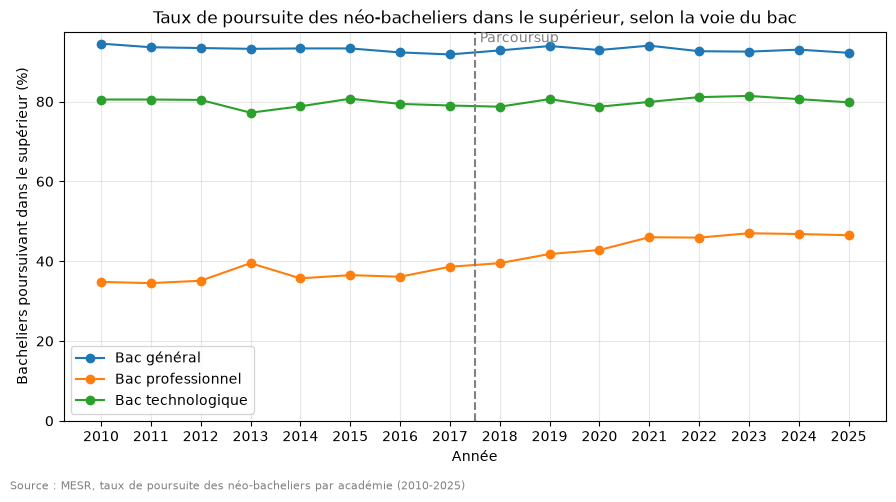

In [5]:
poursuite = preparer_poursuite(charger_poursuite())

# Taux de poursuite (en %) par année et par voie du bac : une colonne par voie
tableau_poursuite = taux_poursuite(poursuite, ["annee", "voie"]).unstack()

courbes(tableau_poursuite,
        titre="Taux de poursuite des néo-bacheliers dans le supérieur, selon la voie du bac",
        axe_y="Bacheliers poursuivant dans le supérieur (%)",
        source="MESR, taux de poursuite des néo-bacheliers par académie (2010-2025)",
        annee_reperee=2018, texte_repere="Parcoursup");

Le taux de poursuite des bacheliers professionnels passe de 34,8 % en 2010 à 38,6 % en 2017, puis à 46,5 % en 2025. Celui des bacheliers généraux (environ 93 %) et technologiques (environ 80 %) reste stable.

On relie ensuite ce fichier aux admis de Parcoursup, par académie et par année. On obtient un tableau avec une ligne par académie et par année : c'est la jointure entre les deux sources. Attention : Parcoursup donne l'académie de la formation, et le fichier de poursuite l'académie du bac.

In [6]:
panel = panel_academies(base, poursuite)

print(panel.shape, "-", panel["academie"].nunique(), "académies")
panel.head()

(240, 13) - 30 académies


,academie,annee,acc_tot,acc_neobac,acc_bp,acc_bt,acc_brs,bacheliers_Bac général,bacheliers_Bac professionnel,bacheliers_Bac technologique,poursuivants_Bac général,poursuivants_Bac professionnel,poursuivants_Bac technologique
0,Aix-Marseille,2018,24485,18607,2068,3850,4363,15646,7291,6172,14346.33570,2568.58960,4569.22180
1,Aix-Marseille,2019,27080,19253,2287,4081,4614,15268,7063,6176,14116.18750,2891.03480,4783.35260
2,Aix-Marseille,2020,28793,21222,2484,4331,6454,17001,7636,6767,15693.57670,3437.52100,4947.35940
3,Aix-Marseille,2021,27614,19604,2143,3542,5888,16450,7179,5887,15659.18680,3515.97980,4461.22740
4,Aix-Marseille,2022,26776,18561,1911,3455,5708,16159,6812,5649,15171.71334,3293.76365,4450.19656


## Bacheliers professionnels et technologiques en BTS et en IUT

Deux règles visent à ouvrir les filières courtes : des places réservées aux bacheliers professionnels en BTS, et, depuis la création du BUT en 2021, un objectif d'environ la moitié de bacheliers technologiques en IUT. On suit la part de ces bacheliers parmi les néo-bacheliers admis.

,Bacs professionnels admis en BTS,Bacs technologiques admis en IUT
session,,
2018,41.2,33.8
2019,40.2,34.2
2020,40.0,34.5
2021,43.1,42.4
2022,43.7,44.0
2023,42.3,43.4
2024,43.0,45.2
2025,44.7,45.5


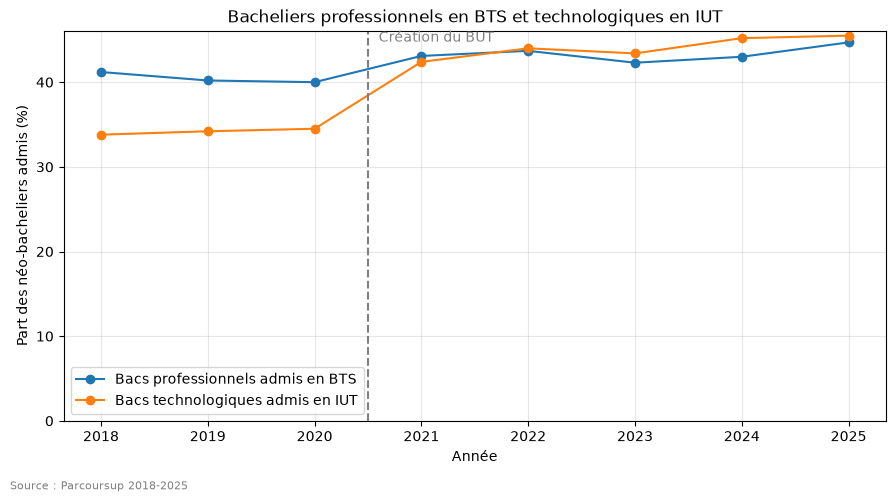

In [7]:
# Deux séries : les bacs pro admis en BTS, les bacs techno admis en IUT (en % des néo-bacheliers admis)
bacs = pd.DataFrame({
    "Bacs professionnels admis en BTS": part_bac_admis(base, "BTS", "acc_bp"),
    "Bacs technologiques admis en IUT": part_bac_admis(base, "IUT", "acc_bt"),
})

courbes(bacs,
        titre="Bacheliers professionnels en BTS et technologiques en IUT",
        axe_y="Part des néo-bacheliers admis (%)",
        source="Parcoursup 2018-2025",
        annee_reperee=2021, texte_repere="Création du BUT");
bacs

La part de bacheliers technologiques parmi les admis en IUT fait un saut en 2021, de 34,5 % à 42,4 %, l'année de la création du BUT, puis atteint 45,5 % en 2025 : l'objectif fixé aux IUT se voit directement dans les données. En BTS, la part de bacheliers professionnels progresse plus lentement, de 41,2 % en 2018 à 44,7 % en 2025.

## Zoom Île-de-France : le secteur unique de 2019

Depuis la session 2019, les académies de Paris, Créteil et Versailles forment un seul secteur dans Parcoursup. On regarde l'effet de ce changement dans les deux sources :
- Parcoursup : la part des admis venant de l'académie de Paris, dans les formations parisiennes ;
- poursuite d'études : la part des bacheliers franciliens qui poursuivent dans une autre académie d'Île-de-France.

,"Admis de l'académie de Paris, dans les formations parisiennes",Bacheliers franciliens poursuivant dans une autre académie d'IDF
2016,NaN,31.1
2017,NaN,30.6
2018,25.1,31.6
2019,20.8,35.2
2020,19.9,36.1
2021,18.9,37.6
2022,17.8,37.9
2023,18.0,37.8
2024,17.7,37.9
2025,16.4,38.0


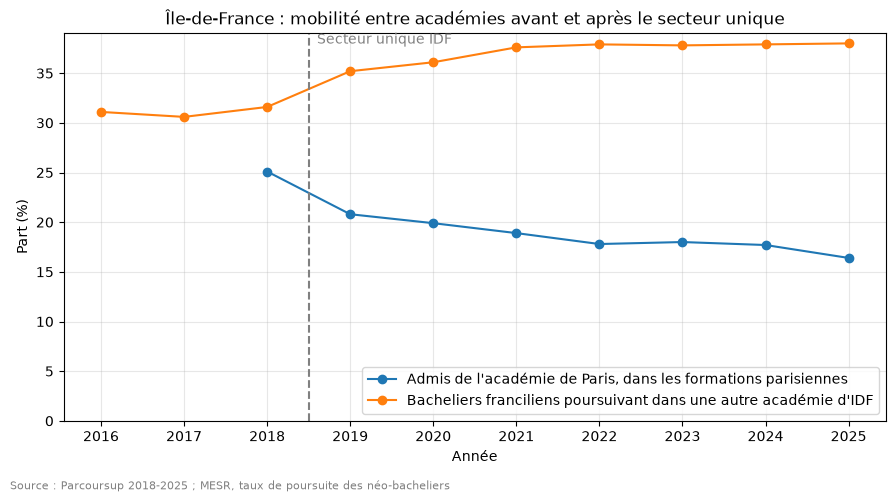

In [8]:
# Les deux indicateurs côte à côte, en %, de 2016 à 2025 (Parcoursup commence en 2018)
idf = pd.DataFrame({
    "Admis de l'académie de Paris, dans les formations parisiennes": part_admis_meme_academie(base, "Paris"),
    "Bacheliers franciliens poursuivant dans une autre académie d'IDF": part_poursuite_autre_academie_idf(poursuite),
}).loc[2016:]

courbes(idf,
        titre="Île-de-France : mobilité entre académies avant et après le secteur unique",
        axe_y="Part (%)",
        source="Parcoursup 2018-2025 ; MESR, taux de poursuite des néo-bacheliers",
        annee_reperee=2019, texte_repere="Secteur unique IDF");
idf

Les deux sources montrent la même rupture en 2019. Dans les formations parisiennes, la part des admis venant de l'académie de Paris passe de 25,1 % en 2018 à 20,8 % en 2019, puis à 16,4 % en 2025. Parmi les bacheliers franciliens qui poursuivent dans le supérieur, la part de ceux qui étudient dans une autre académie d'Île-de-France reste entre 30 et 32 % jusqu'en 2018, puis passe à 35,2 % en 2019 et à 38 % en 2025. Les formations parisiennes accueillent donc davantage de bacheliers de Créteil et de Versailles. Ces données ne disent pas si ces nouveaux admis viennent de milieux moins favorisés.

## Formations sélectives et non sélectives : la place des boursiers

La sélection est l'étape où Parcoursup peut favoriser ou freiner la démocratisation : ce sont les formations sélectives qui choisissent leurs admis. On les compare aux formations non sélectives (surtout les licences), qui accueillent une grande partie des boursiers et des bacheliers professionnels.

Les formations sélectives représentent 79 % des formations de la base.

In [9]:
formations_selectives = base_selective(base)

print(len(formations_selectives), "formations sélectives sur", len(base))

81919 formations sélectives sur 104274


Pour mesurer la place des boursiers, on ne compare pas la part de boursiers d'une année à l'autre : le nombre de boursiers recensés fait un saut en 2020 et chute en 2025, aussi bien parmi les vœux que parmi les admis. Ces sauts viennent du comptage, pas de la sélection.

On compare donc, la même année, la part de boursiers parmi les vœux des néo-bacheliers et parmi les néo-bacheliers admis. Le rapport des deux vaut 1 si les boursiers sont aussi présents parmi les admis que parmi les vœux ; au-dessus de 1, ils sont plus présents parmi les admis.

selective,Formations non sélectives,Formations sélectives
session,,
2018,1.16,1.18
2019,1.15,1.04
2020,1.23,1.04
2021,1.22,1.07
2022,1.19,1.06
2023,1.18,1.10
2024,1.18,1.11
2025,1.15,1.06


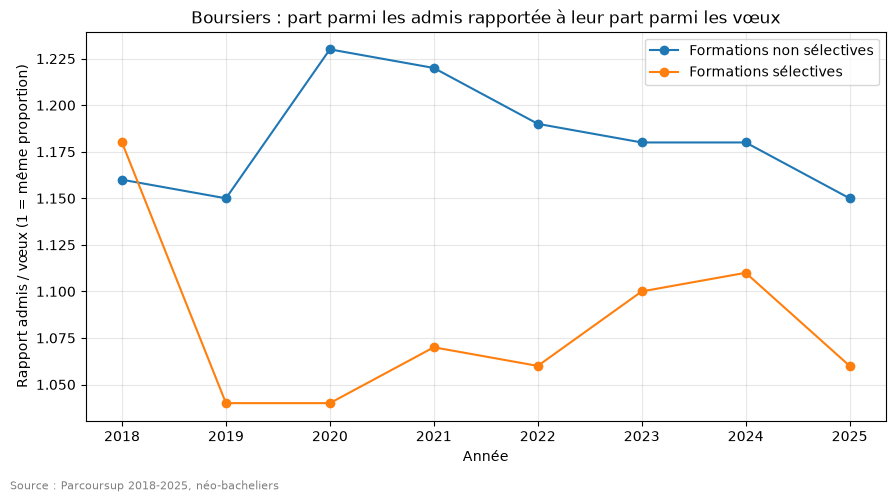

In [10]:
boursiers = boursiers_admis_et_candidats(base, ["session", "selective"])

# Rapport admis / vœux : une colonne pour les non sélectives (0) et une pour les sélectives (1)
rapport_boursiers = boursiers["rapport"].unstack().rename(columns={0.0: "Formations non sélectives",
                                                                   1.0: "Formations sélectives"})

courbes(rapport_boursiers,
        titre="Boursiers : part parmi les admis rapportée à leur part parmi les vœux",
        axe_y="Rapport admis / vœux (1 = même proportion)",
        source="Parcoursup 2018-2025, néo-bacheliers",
        depuis_zero=False);
rapport_boursiers

Chaque année, le rapport est supérieur à 1 : les boursiers sont un peu plus présents parmi les admis que parmi les vœux. L'écart est plus faible dans les formations sélectives (entre 1,04 et 1,11 depuis 2019) que dans les non sélectives (entre 1,15 et 1,23). Il ne s'élargit pas depuis 2019. En 2018, la sélectivité est reportée depuis 2020 : la valeur de cette année est à lire avec prudence.

Limites : ce sont des vœux et non des candidats (un candidat fait plusieurs vœux), et un rapport supérieur à 1 peut aussi venir des choix des candidats (vœux plus nombreux chez les non-boursiers, par exemple). On regarde ensuite le détail par filière parmi les formations sélectives.

In [11]:
# Même rapport parmi les formations sélectives, pour les principales filières
principales = formations_selectives[formations_selectives["filiere"].isin(["CPGE", "BTS", "IUT"])]
boursiers_admis_et_candidats(principales, ["session", "filiere"])["rapport"].unstack()

filiere,BTS,CPGE,IUT
session,,,
2018,1.00,1.13,0.99
2019,1.00,1.21,1.05
2020,1.00,1.10,1.05
2021,1.01,1.13,1.09
2022,0.99,1.14,1.08
2023,1.01,1.14,1.07
2024,1.00,1.11,1.05
2025,0.97,1.12,0.99


En BTS, le rapport reste proche de 1 chaque année : les boursiers sont admis dans la même proportion que leur part dans les vœux. En CPGE, il est plus élevé (entre 1,10 et 1,21) : parmi les néo-bacheliers admis en CPGE, les boursiers sont un peu plus présents que parmi les vœux. Ce sont des descriptions : elles ne disent pas si cet écart vient de la sélection des formations (par exemple des quotas de boursiers) ou des choix des candidats.

## Le milieu social des lycées qui accueillent les CPGE et les BTS

On classe les formations installées dans un lycée en quatre groupes de même taille selon l'IPS du lycée, des moins favorisés aux plus favorisés, puis on calcule la part de boursiers parmi les néo-bacheliers admis. Comme le nombre de boursiers recensés change en 2020 et en 2025, on compare les groupes entre eux la même année, plutôt que les niveaux d'une année à l'autre.

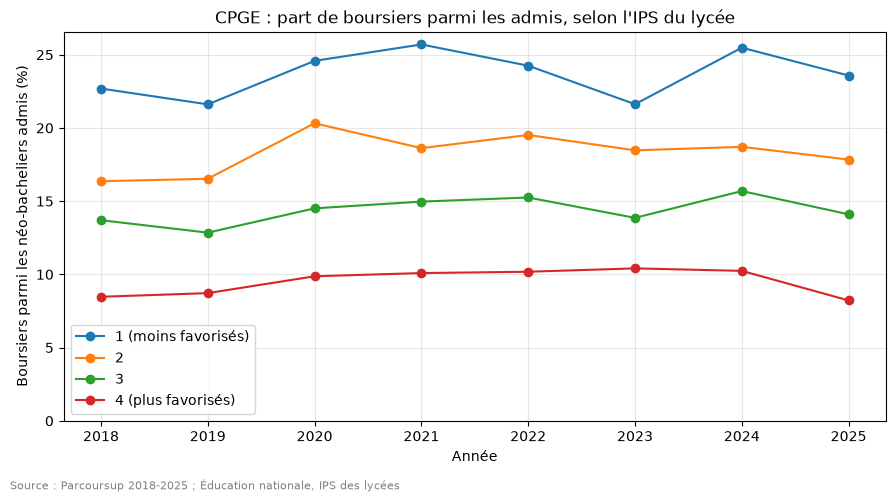

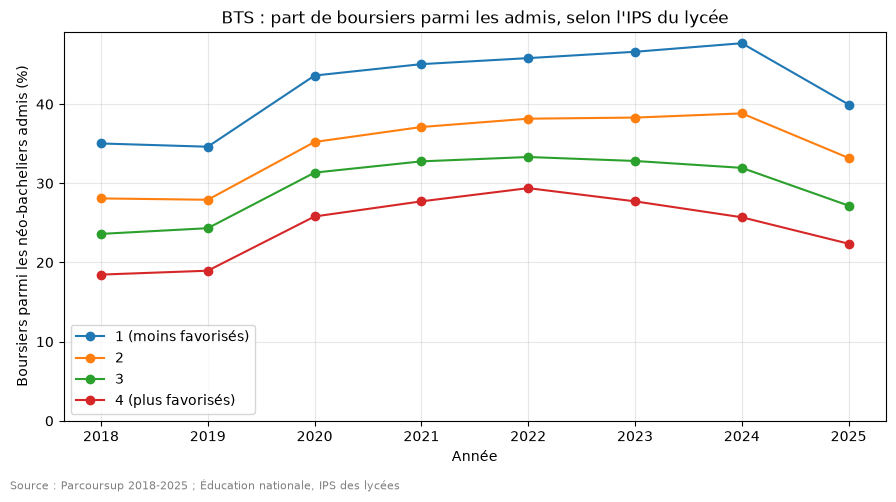

In [12]:
base = ajouter_tranche_ips(base)

for filiere in ["CPGE", "BTS"]:
    formations = base[base["filiere"] == filiere]
    par_tranche = boursiers_admis_et_candidats(formations, ["session", "tranche_ips"])
    courbes(par_tranche["part_admis"].unstack(),
            titre=f"{filiere} : part de boursiers parmi les admis, selon l'IPS du lycée",
            axe_y="Boursiers parmi les néo-bacheliers admis (%)",
            source="Parcoursup 2018-2025 ; Éducation nationale, IPS des lycées")

L'écart selon le milieu social du lycée est net et ne se réduit pas. En CPGE, les boursiers représentent environ 22 à 26 % des admis dans les lycées les moins favorisés, contre 8 à 10 % dans les plus favorisés, chaque année de 2018 à 2025. En BTS, l'écart est du même ordre : 35 % contre 18 % en 2018, 40 % contre 22 % en 2025. Les sauts de 2020 et 2025 touchent tous les groupes en même temps : ils viennent du comptage des boursiers, comme vu plus haut.

Autrement dit, sur cette période, Parcoursup n'a pas rapproché la composition sociale des CPGE et des BTS selon le lycée qui les accueille. Limite : l'IPS décrit les élèves du lycée (en seconde, première et terminale), pas ceux de la CPGE ou du BTS eux-mêmes.